<a href="https://colab.research.google.com/github/Josphinity/Course-project/blob/main/Discovering_patterns_in_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from google.colab import files
uploaded=files.upload()
df=pd.read_csv("ai4i2020.csv")
print("Dataset shape:",df.shape)
print("\nColumn names:")
print(df.columns.tolist())
df.head()

Saving ai4i2020.csv to ai4i2020 (1).csv
Dataset shape: (10000, 14)

Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
features=['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
x=df[features]
print("Features selected:",features)
print("Shape of clustering data",x.shape)
x.head()

Features selected: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Shape of clustering data (10000, 5)


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,298.1,308.6,1551,42.8,0
1,298.2,308.7,1408,46.3,3
2,298.1,308.5,1498,49.4,5
3,298.2,308.6,1433,39.5,7
4,298.2,308.7,1408,40.0,9


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)
print("Scaled data shape:",x_scaled.shape)
print("First five scaled data rows:")
print(x_scaled[:5])

Scaled data shape: (10000, 5)
First five scaled data rows:
[[-9.52389443e-01 -9.47359888e-01  6.81851403e-02  2.82199756e-01
  -1.69598374e+00]
 [-9.02393410e-01 -8.79959002e-01 -7.29471505e-01  6.33308020e-01
  -1.64885170e+00]
 [-9.52389443e-01 -1.01476077e+00 -2.27449840e-01  9.44289625e-01
  -1.61743034e+00]
 [-9.02393410e-01 -9.47359888e-01 -5.90021043e-01 -4.88451785e-02
  -1.58600898e+00]
 [-9.02393410e-01 -8.79959002e-01 -7.29471505e-01  1.31314491e-03
  -1.55458761e+00]]


In [7]:
from sklearn.cluster import KMeans
kmeans_3=KMeans(n_clusters=3,random_state=42,n_init=10)
cluster_labels= kmeans_3.fit_predict(x_scaled)
df["Cluster"]=cluster_labels
print("Cluster assignments:")
print(df["Cluster"].value_counts().sort_index())
print("\nInertia:",kmeans_3.inertia_)

Cluster assignments:
Cluster
0    3930
1    4017
2    2053
Name: count, dtype: int64

Inertia: 28305.69356884031


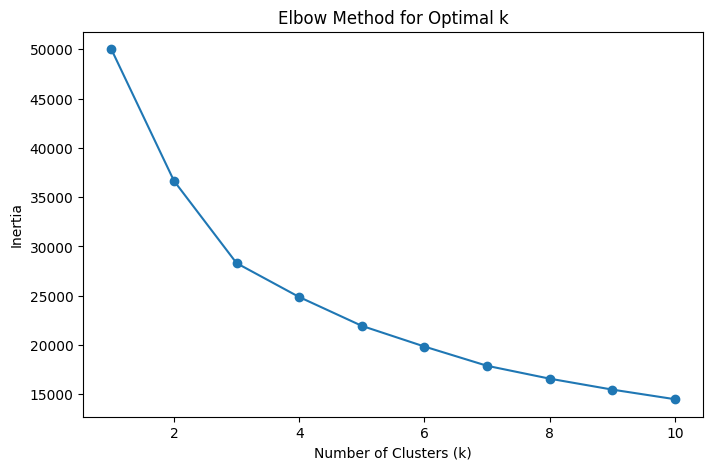

In [12]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
inertia_values=[]
k_values = range(1,11)
for k in k_values:
  kmeans_model=KMeans(n_clusters=k,random_state=42,n_init=10)
  kmeans_model.fit(x_scaled)
  inertia_values.append(kmeans_model.inertia_)

plt.figure(figsize=(8,5))
plt.plot(k_values, inertia_values, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.show()

In [14]:
cluster_profiles= df.groupby("Cluster")[["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]].mean().round(2)
print("Average characteristics of each cluster:")
display(cluster_profiles)

Average characteristics of each cluster:


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Cluster,,,,,
0,301.72,311.25,1469.81,43.64,110.36
1,298.26,308.74,1474.14,43.26,104.62
2,300.12,310.10,1797.26,26.57,109.85


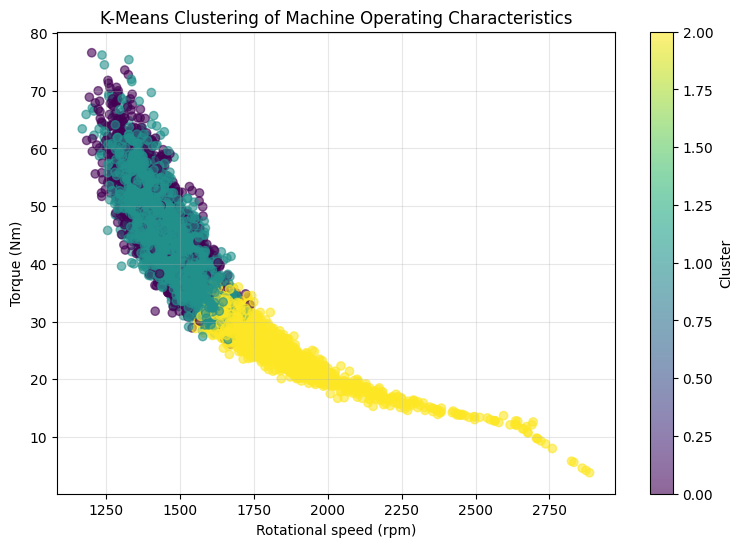

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    df["Rotational speed [rpm]"],
    df["Torque [Nm]"],
    c=df["Cluster"],
    cmap="viridis",
    alpha=0.6
)

plt.xlabel("Rotational speed (rpm)")
plt.ylabel("Torque (Nm)")
plt.title("K-Means Clustering of Machine Operating Characteristics")

colorbar = plt.colorbar(scatter)
colorbar.set_label("Cluster")

plt.grid(True, alpha=0.3)
plt.show()

## Model Results and Discussion

### Method

K-Means clustering was applied to the AI4I 2020 Predictive Maintenance Dataset to identify groups of machines with similar operating characteristics. Five numerical features were selected: air temperature, process temperature, rotational speed, torque, and tool wear. The features were standardized before clustering so that differences in their numerical scales would not dominate the distance calculations.

### Selection of the Number of Clusters

The elbow method was used to compare K-Means models with different numbers of clusters. Inertia decreased substantially from one to three clusters and then continued to decrease more gradually. Based on this pattern, three clusters were selected as a reasonable choice, although the elbow was not sharply defined.

### Results and Interpretation

The selected model assigned the 10,000 machine records to three clusters: Cluster 0 contained 3,930 records, Cluster 1 contained 4,017 records, and Cluster 2 contained 2,053 records.

The cluster profiles showed that Cluster 0 had the highest average air temperature (301.72 K), process temperature (311.25 K), and torque (43.64 Nm). Cluster 1 had the lowest average air temperature (298.26 K) and process temperature (308.74 K). Cluster 2 was characterized by the highest average rotational speed (1,797.26 rpm) and the lowest average torque (26.57 Nm).

The scatter plot of rotational speed against torque showed a distinct group at higher rotational speeds and lower torque, corresponding to Cluster 2. Clusters 0 and 1 overlapped more substantially in this two-dimensional view.

### Discussion and Limitations

The results demonstrate how unsupervised learning can reveal different operating patterns in machine data without using predefined group labels during training. These groups could be investigated further to understand machine operating conditions and support exploratory maintenance analysis.

However, the clusters do not automatically indicate whether a machine is healthy or faulty. Further analysis, including comparison with recorded failure outcomes, would be needed to investigate any relationship between the clusters and machine failures.